# FitNets KD Student — DNN Teacher (Keras -> PyTorch)

Notebook train **1 student** bằng **FitNets** (Romero et al., ICLR 2015) — huấn luyện 2 giai đoạn:

- **Giai đoạn 1 — Hint-based Training (Eq. 3):** student học "bắt chước" feature middle-layer của teacher (hint) qua 1 regressor.
- **Giai đoạn 2 — Knowledge Distillation (Eq. 2):** CE(y, P_S) + lambda·KL(P_T^tau ‖ P_S^tau).

**Khác biệt so với bản SSL-CL-DNN:**
- Teacher: **DNN thuần [256,256,256]**, được train & lưu bằng **TensorFlow/Keras** (`best_model_100epoch.keras`).
  Notebook này **load Keras model, tự động convert trọng số sang PyTorch**, lưu lại `.pth` để cache, rồi
  chạy toàn bộ pipeline FitNets bằng PyTorch y hệt bản gốc.
- Student: **MiniDNN [64,64,64]** (chia đều /4, giữ nguyên độ sâu — không phải MiniDNNEncoder/MiniClassifier của SSL).
- `lr`, `batch_size`: lấy từ Optuna teacher DNN (0.001685 / 512), **không đổi so với bản SSL**.
- Toàn bộ hyperparameter FitNets (`HINT_EPOCHS`, `KD_EPOCHS`, `LAMBDA_INIT/FINAL`, `TAU`) **giữ nguyên y hệt** notebook gốc.


## Cell 1 — Cấu hình & Import

In [1]:
!pip install -q pyarrow pandas scikit-learn torch tensorflow matplotlib seaborn

import os, gc, time, glob, warnings, json, tracemalloc
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

import torch
import torch.nn as nn
import torch.nn.functional as F
import torch.optim as optim
from torch.utils.data import DataLoader, Dataset
from sklearn.metrics import (
    classification_report, roc_auc_score,
    accuracy_score, confusion_matrix, f1_score
)

warnings.filterwarnings('ignore')

# ── Duong dan ────────────────────────────────────────────────────────────────
INPUT_DIR    = '/kaggle/input/datasets/rsnngo/37ft-thang3737'
TEACHER_DIR  = '/kaggle/input/datasets/rsnngo/teacher-model-thang3737'
TEACHER_KERAS_PATH = f'{TEACHER_DIR}/dnn_after_optuna_37ft.keras'      # INPUT: model Keras that
TEACHER_PTH_CACHE  = '/kaggle/working/teacher_dnn_converted.pth'     # OUTPUT: cache PyTorch (tu dong tao)

OUTPUT_DIR   = '/kaggle/working/'
TRAIN_FILE   = os.path.join(INPUT_DIR, 'train_standard_p3.2.parquet')
VAL_FILE     = os.path.join(INPUT_DIR, 'val_standard_p3.2.parquet')
TEST_FILE    = os.path.join(INPUT_DIR, 'test_standard_p3.2.parquet')
CLASS_WEIGHTS_JSON = os.path.join(INPUT_DIR, 'class_weights_p3.2.json')

# Output cho FitNets
FITNET_PATH     = os.path.join(OUTPUT_DIR, 'student_dnn_fitnets__classw3_37ft.pth')
FITNET_CKPT_DIR = os.path.join(OUTPUT_DIR, 'ckpt_fitnets_dnn')
for d in [OUTPUT_DIR, FITNET_CKPT_DIR]:
    os.makedirs(d, exist_ok=True)

# ── Hang so model ─────────────────────────────────────────────────────────────
NUM_FEATURES = 37
NUM_CLASSES  = 8
LABEL_COL    = 'label'
ARCHITECTURE_TEACHER = [256, 256, 256]   # DNN thuan
ARCHITECTURE_STUDENT = [64, 64, 64]      # MiniDNN -- chia deu /4, giu nguyen do sau
LABEL_NAMES = {0:'Benign',1:'DDoS',2:'DoS',3:'BruteForce',
               4:'Spoofing',5:'Recon',6:'Web-Based',7:'Mirai'}
CLASS_NAMES = [LABEL_NAMES[i] for i in range(NUM_CLASSES)]
COLORS = ['#4C9BE8','#E84C4C','#F5A623','#9B59B6',
          '#2ECC71','#1ABC9C','#8B4513','#607D8B']

# ── Hyperparameters training (lr & batch tu Optuna teacher DNN, KHONG doi) ────
BATCH_SIZE       = 512        # tu optuna-dnn-37ft.ipynb
LR               = 0.001685   # tu optuna-dnn-37ft.ipynb
WEIGHT_DECAY     = 0.0         # DNN: Adam, KHONG weight decay
CLASS_WEIGHT_MAX = 3.0       # giu nguyen nhu ban FitNets goc (SSL-CL-DNN)
CHECKPOINT_EVERY = 5
RANDOM_SEED      = 42

# ── FitNets hyperparams (GIU NGUYEN y het ban goc, theo paper Romero et al. 2015) ──
HINT_EPOCHS      = 50         # giai doan 1: hint-based pre-training
KD_EPOCHS        = 50         # giai doan 2: KD
N_EPOCHS         = HINT_EPOCHS + KD_EPOCHS   # tong = 100

# Hint/guided layer indices -- chon "sau ReLU cua block giua" (block 2/3),
# GIU NGUYEN logic voi ban goc: teacher goc (4 block) lay hint sau block 2/4 (50% do sau);
# DNN thuan (3 block) lay hint sau block 2/3 (~67% do sau, gan nhat voi 50%).
# QUAN TRONG: thu tu phai khop Keras: Dense(activation='relu') fuse Linear+ReLU
# TRUOC roi moi BatchNorm -> PyTorch la Linear->ReLU->BatchNorm->Dropout (4 sub-layer/block).
#   block1: idx 0-3 | block2: idx 4-7 | block3: idx 8-11 | final Linear: idx 12
#   -> hint/guided = ReLU cuoi block2 = idx 5  [4=Linear,5=ReLU,6=BN,7=Dropout]
TEACHER_HINT_IDX   = 5
STUDENT_GUIDED_IDX = 5
HINT_DIM   = 256              # chieu hint (teacher block2 width)
GUIDED_DIM = 64               # chieu guided (student block2 width)

# KD (Eq. 2): lambda giam tuyen tinh 4 -> 1, tau = 3 (GIU NGUYEN nhu ban goc)
LAMBDA_INIT  = 4.0
LAMBDA_FINAL = 1.0
TAU          = 3.0

torch.manual_seed(RANDOM_SEED)
np.random.seed(RANDOM_SEED)
DEVICE = torch.device('cuda' if torch.cuda.is_available() else 'cpu')

print('=' * 62)
print('  FitNets KD Student -- DNN Teacher (Keras->PyTorch, 2-stage)')
print('=' * 62)
print(f'  Device       : {DEVICE}')
print(f'  Batch size   : {BATCH_SIZE}   LR: {LR}   WD: {WEIGHT_DECAY}')
print(f'  Tong epoch   : {N_EPOCHS}  (hint {HINT_EPOCHS} + KD {KD_EPOCHS})')
print(f'  Hint  (teacher, dim={HINT_DIM})  <-  Guided (student, dim={GUIDED_DIM})')
print(f'  Regressor    : Linear({GUIDED_DIM} -> {HINT_DIM}) + ReLU')
print(f'  KD           : lambda {LAMBDA_INIT} -> {LAMBDA_FINAL} (linear), tau = {TAU}')
print('  Scheduler    : KHONG dung (LR co dinh), luu best epoch theo val loss')
print('=' * 62)


  FitNets KD Student -- DNN Teacher (Keras->PyTorch, 2-stage)
  Device       : cuda
  Batch size   : 512   LR: 0.001685   WD: 0.0
  Tong epoch   : 100  (hint 50 + KD 50)
  Hint  (teacher, dim=256)  <-  Guided (student, dim=64)
  Regressor    : Linear(64 -> 256) + ReLU
  KD           : lambda 4.0 -> 1.0 (linear), tau = 3.0
  Scheduler    : KHONG dung (LR co dinh), luu best epoch theo val loss


## Load class weights (`weights_balanced`, clip max=3)

In [2]:
def load_class_weights(json_path, num_classes=NUM_CLASSES, clip_max=CLASS_WEIGHT_MAX):
    """Doc class_weights_p3.json, lay 'weights_balanced', clip max."""
    with open(json_path, 'r') as f:
        raw = json.load(f)
    weights = np.ones(num_classes, dtype=np.float32)
    if isinstance(raw, dict) and any(k in raw for k in ('weights_balanced','class_weights','weights')):
        for key in ('weights_balanced','class_weights','weights'):
            if key in raw:
                arr = raw[key]
                assert len(arr) == num_classes, f'{key} len {len(arr)} != {num_classes}'
                weights = np.array(arr, dtype=np.float32)
                print(f'  Lay class weight tu key "{key}"')
                break
    elif isinstance(raw, list):
        assert len(raw) == num_classes
        weights = np.array(raw, dtype=np.float32)
    elif isinstance(raw, dict):
        name_to_idx = {v: k for k, v in LABEL_NAMES.items()}
        for k, val in raw.items():
            idx = int(k) if str(k).isdigit() else name_to_idx[k]
            weights[idx] = float(val)
    weights_clipped = np.minimum(weights, clip_max)
    return torch.tensor(weights_clipped, dtype=torch.float32, device=DEVICE), weights

try:
    class_weights, class_weights_raw = load_class_weights(CLASS_WEIGHTS_JSON)
    print(f'Class weights (balanced -> clip max={CLASS_WEIGHT_MAX:.1f}):')
    for i in range(NUM_CLASSES):
        clip = ' <- CLIP' if class_weights_raw[i] > CLASS_WEIGHT_MAX else ''
        print(f'  [{i}] {LABEL_NAMES[i]:12s}: {class_weights_raw[i]:8.4f} -> {class_weights[i].item():.4f}{clip}')
except FileNotFoundError:
    print(f'CANH BAO: khong thay {CLASS_WEIGHTS_JSON} -> class_weights=None')
    class_weights = None


  Lay class weight tu key "weights_balanced"
Class weights (balanced -> clip max=3.0):
  [0] Benign      :   0.8334 -> 0.8334
  [1] DDoS        :   0.2914 -> 0.2914
  [2] DoS         :   0.9012 -> 0.9012
  [3] BruteForce  :  69.7046 -> 3.0000 <- CLIP
  [4] Spoofing    :   2.0023 -> 2.0023
  [5] Recon       :   1.4567 -> 1.4567
  [6] Web-Based   :  36.8116 -> 3.0000 <- CLIP
  [7] Mirai       :   0.9697 -> 0.9697


## Cell 2 — Dataset (giữ nguyên)

In [3]:
class ParquetDataset(Dataset):
    def __init__(self, path, label_col=LABEL_COL):
        df = pd.read_parquet(path)
        feat_cols = [c for c in df.columns if c != label_col]
        assert len(feat_cols) == NUM_FEATURES, \
            f'Feature mismatch: {len(feat_cols)} != {NUM_FEATURES}'
        self.X = torch.from_numpy(df[feat_cols].to_numpy(dtype=np.float32))
        self.y = torch.from_numpy(df[label_col].to_numpy(dtype=np.int64))
        print(f'  {path.split("/")[-1]}: {len(self.X):,} mau')
    def __len__(self):        return len(self.X)
    def __getitem__(self, i): return self.X[i], self.y[i]

print('Dang doc du lieu ...')
train_ds = ParquetDataset(TRAIN_FILE)
val_ds   = ParquetDataset(VAL_FILE)
test_ds  = ParquetDataset(TEST_FILE)

kw = dict(batch_size=BATCH_SIZE, num_workers=2, pin_memory=True)
train_loader = DataLoader(train_ds, shuffle=True,  **kw)
val_loader   = DataLoader(val_ds,   shuffle=False, **kw)
test_loader  = DataLoader(test_ds,  shuffle=False, **kw)
print(f'Dataset san sang | train {len(train_loader):,} batches')


Dang doc du lieu ...
  train_standard_p3.2.parquet: 4,468,344 mau
  val_standard_p3.2.parquet: 1,117,087 mau
  test_standard_p3.2.parquet: 1,396,358 mau
Dataset san sang | train 8,728 batches


## Cell 3 — Kiến trúc Teacher & Student (FitNets)

- Teacher `DNNPlain`: kiến trúc monolithic Linear→BN→ReLU→Dropout ×3, khớp `optuna-dnn-37ft.ipynb`.
- **Load Keras → convert PyTorch**: `load_teacher_from_keras()` đọc `best_model_100epoch.keras`,
  copy trọng số Dense/BatchNorm sang layer PyTorch tương ứng (transpose weight matrix theo đúng convention
  Keras `(in,out)` vs PyTorch `(out,in)`), có sanity-check argmax khớp 100% trước khi dùng.
- Student `FitNetStudent`: MiniDNN [64,64,64], `forward_hint`/`forward_guided` lấy feature tại `STUDENT_GUIDED_IDX`.


In [4]:
# ── Teacher: DNN thuan, co forward_hint de lay feature middle-layer ──────────
# QUAN TRONG: thu tu phai KHOP DUNG voi Keras goc:
#   Keras: layers.Dense(units, activation='relu')(x) -> BatchNormalization()(x) -> Dropout(0.1)(x)
#   Tuc la Linear+ReLU FUSE truoc, roi moi den BatchNorm, roi Dropout.
#   => PyTorch phai la: Linear -> ReLU -> BatchNorm1d -> Dropout (KHONG PHAI Linear->BN->ReLU->Dropout!)
class DNNPlainWithHint(nn.Module):
    def __init__(self, in_dim=NUM_FEATURES, hidden=ARCHITECTURE_TEACHER,
                 num_classes=NUM_CLASSES, dropout=0.1):
        super().__init__()
        layers = []
        d = in_dim
        for units in hidden:
            layers += [nn.Linear(d, units), nn.ReLU(), nn.BatchNorm1d(units, eps=1e-3), nn.Dropout(dropout)]
            d = units
        layers += [nn.Linear(d, num_classes)]
        self.net = nn.Sequential(*layers)

    def forward(self, x):
        return self.net(x)   # logits

    def forward_hint(self, x, hint_idx=TEACHER_HINT_IDX):
        """Tra (logits, hint feature o middle layer)."""
        hint = None
        h = x
        for i, layer in enumerate(self.net):
            h = layer(h)
            if i == hint_idx:
                hint = h
        return h, hint   # h o day la logits (da qua het net)


# ── Student sub-modules: MiniDNN [64,64,64] ──────────────────────────────────
# Cung thu tu Linear->ReLU->BatchNorm->Dropout de dong bo voi teacher va voi
# ban Keras (student-dnn-vanilla-kd.ipynb dung Dense(activation='relu')->BN->Dropout).
class MiniDNNWithGuided(nn.Module):
    def __init__(self, in_dim=NUM_FEATURES, hidden=ARCHITECTURE_STUDENT,
                 num_classes=NUM_CLASSES, dropout=0.1):
        super().__init__()
        layers = []
        d = in_dim
        for units in hidden:
            layers += [nn.Linear(d, units), nn.ReLU(), nn.BatchNorm1d(units, eps=1e-3), nn.Dropout(dropout)]
            d = units
        layers += [nn.Linear(d, num_classes)]
        self.net = nn.Sequential(*layers)

    def forward(self, x):
        return self.net(x)   # logits

    def forward_guided(self, x, guided_idx=STUDENT_GUIDED_IDX):
        """Tra (logits, guided feature o middle layer)."""
        guided = None
        h = x
        for i, layer in enumerate(self.net):
            h = layer(h)
            if i == guided_idx:
                guided = h
        return h, guided


class FitNetStudent(nn.Module):
    def __init__(self):
        super().__init__()
        self.model = MiniDNNWithGuided()

    def forward(self, x):
        return self.model(x)   # logits

    def forward_guided(self, x):
        return self.model.forward_guided(x)


# ── Regressor (Eq. 3): guided (64) -> hint (256), cung non-linearity ReLU ────
class Regressor(nn.Module):
    def __init__(self, in_dim=GUIDED_DIM, out_dim=HINT_DIM):
        super().__init__()
        self.fc  = nn.Linear(in_dim, out_dim)
        self.act = nn.ReLU()   # hint (teacher middle) la output sau ReLU -> khop non-linearity
    def forward(self, x):
        return self.act(self.fc(x))


def count_params(m): return sum(p.numel() for p in m.parameters())

print(f'Student params (FitNetStudent) : {count_params(FitNetStudent()):,}')


Student params (FitNetStudent) : 11,656


## Cell 4 — Loss Functions (giữ nguyên)

In [5]:
def hint_loss(hint_teacher, guided_student, regressor):
    """Eq. (3): L_HT = 1/2 * || u_h(x) - r(v_g(x)) ||^2  (MSE)."""
    pred = regressor(guided_student)
    return 0.5 * F.mse_loss(pred, hint_teacher, reduction='mean')


def kd_loss(logits_s, logits_t, labels, lam, tau=TAU):
    """Eq. (2): H(y, P_S) + lambda * H(P_T^tau, P_S^tau).
       Dung KL(P_T || P_S) cho so hang cross-entropy softened; nhan tau^2 (chuan Hinton)."""
    p_t     = F.softmax(logits_t / tau, dim=-1)
    log_p_s = F.log_softmax(logits_s / tau, dim=-1)
    L_soft  = F.kl_div(log_p_s, p_t, reduction='batchmean') * (tau ** 2)
    L_ce    = F.cross_entropy(logits_s, labels, weight=class_weights)  # class weight vao CE
    return L_ce + lam * L_soft


def lambda_at(epoch_in_kd, total_kd=KD_EPOCHS,
              lam0=LAMBDA_INIT, lam1=LAMBDA_FINAL):
    """lambda giam tuyen tinh tu lam0 -> lam1 doc theo giai doan KD (theo paper)."""
    if total_kd <= 1:
        return lam1
    frac = epoch_in_kd / (total_kd - 1)
    return lam0 + (lam1 - lam0) * frac

print('Loss functions san sang')
print(f'  hint_loss : 1/2 * MSE(hint_teacher, regressor(guided_student))')
print(f'  kd_loss   : CE + lambda * tau^2 * KL,  tau = {TAU}')
print(f'  lambda    : {LAMBDA_INIT} -> {LAMBDA_FINAL} tuyen tinh trong {KD_EPOCHS} epoch KD')


Loss functions san sang
  hint_loss : 1/2 * MSE(hint_teacher, regressor(guided_student))
  kd_loss   : CE + lambda * tau^2 * KL,  tau = 3.0
  lambda    : 4.0 -> 1.0 tuyen tinh trong 50 epoch KD


## Cell 5 — Load Teacher (Keras → PyTorch, frozen)

Convert trọng số Keras sang PyTorch, có sanity-check argmax khớp 100% trước khi dùng cho FitNets.


In [6]:
import tensorflow as tf

def load_teacher_from_keras(keras_path, cache_path=None):
    """Load model Keras (Dense->BN->ReLU->Dropout x3 -> Dense softmax), build lai
    kien truc tuong duong trong PyTorch (khong softmax, co forward_hint), copy trong so."""
    keras_model = tf.keras.models.load_model(keras_path)
    torch_model = DNNPlainWithHint()

    # Cac layer Keras co trong so, theo dung thu tu: Dense, BN, Dense, BN, Dense, BN, Dense(out)
    keras_weighted_layers = [l for l in keras_model.layers if l.get_weights()]

    # Cac sub-module PyTorch tuong ung, theo dung thu tu trong self.net
    torch_linear_bn = [m for m in torch_model.net if isinstance(m, (nn.Linear, nn.BatchNorm1d))]

    assert len(keras_weighted_layers) == len(torch_linear_bn), (
        f'So layer co trong so khong khop: Keras={len(keras_weighted_layers)}, '
        f'PyTorch={len(torch_linear_bn)}. Kiem tra lai ARCHITECTURE_TEACHER co dung [256,256,256].'
    )

    for k_layer, t_layer in zip(keras_weighted_layers, torch_linear_bn):
        wts = k_layer.get_weights()
        if isinstance(t_layer, nn.Linear):
            W, b = wts                                  # Keras Dense: W shape (in, out)
            t_layer.weight.data = torch.from_numpy(W.T).float()   # PyTorch Linear: (out, in)
            t_layer.bias.data   = torch.from_numpy(b).float()
        elif isinstance(t_layer, nn.BatchNorm1d):
            gamma, beta, moving_mean, moving_var = wts
            t_layer.weight.data       = torch.from_numpy(gamma).float()
            t_layer.bias.data         = torch.from_numpy(beta).float()
            t_layer.running_mean.data = torch.from_numpy(moving_mean).float()
            t_layer.running_var.data  = torch.from_numpy(moving_var).float()

    torch_model.eval()
    if cache_path:
        torch.save(torch_model.state_dict(), cache_path)
        print(f'  Da cache PyTorch checkpoint -> {cache_path}')
    return torch_model, keras_model


print('Load & convert teacher tu Keras sang PyTorch ...')
t_model, _keras_teacher = load_teacher_from_keras(TEACHER_KERAS_PATH, cache_path=TEACHER_PTH_CACHE)
t_model.to(DEVICE).eval()
for p in t_model.parameters(): p.requires_grad = False

t_params = count_params(t_model)
print(f'Teacher loaded | Params: {t_params:,} | Frozen: True')

@torch.no_grad()
def teacher_forward(x):
    """Tra (logits_t, hint_t) -- hint la feature middle layer, HINT_DIM chieu."""
    logits_t, hint = t_model.forward_hint(x)
    return logits_t, hint

# ── Sanity check: PyTorch converted model phai cho argmax KHOP 100% voi Keras goc ──
_x_np = train_ds.X[:256].numpy()
_x_torch = train_ds.X[:256].to(DEVICE)

_keras_pred = np.argmax(_keras_teacher.predict(_x_np, verbose=0), axis=1)
_logits_t, _hint_t = teacher_forward(_x_torch)
_torch_pred = _logits_t.argmax(dim=1).cpu().numpy()

assert np.array_equal(_keras_pred, _torch_pred), (
    'CONVERT LOI: PyTorch teacher KHONG khop Keras teacher! Kiem tra lai thu tu layer / weight transpose.'
)
print(f'Sanity check: Keras vs PyTorch teacher argmax khop 100% ({len(_keras_pred)} mau)')
print(f'Teacher sanity: logits {tuple(_logits_t.shape)}, hint {tuple(_hint_t.shape)} '
      f'(ky vong [256, {HINT_DIM}])')
assert _hint_t.shape[1] == HINT_DIM, 'Hint dim khong khop!'
del _x_np, _x_torch, _keras_pred, _logits_t, _hint_t, _torch_pred
gc.collect()


Load & convert teacher tu Keras sang PyTorch ...


I0000 00:00:1785726023.683073      22 gpu_device.cc:2020] Created device /job:localhost/replica:0/task:0/device:GPU:0 with 13754 MB memory:  -> device: 0, name: Tesla T4, pci bus id: 0000:00:04.0, compute capability: 7.5
I0000 00:00:1785726023.685205      22 gpu_device.cc:2020] Created device /job:localhost/replica:0/task:0/device:GPU:1 with 13756 MB memory:  -> device: 1, name: Tesla T4, pci bus id: 0000:00:05.0, compute capability: 7.5


  Da cache PyTorch checkpoint -> /kaggle/working/teacher_dnn_converted.pth
Teacher loaded | Params: 144,904 | Frozen: True


I0000 00:00:1785726026.007659      82 device_compiler.h:196] Compiled cluster using XLA!  This line is logged at most once for the lifetime of the process.


Sanity check: Keras vs PyTorch teacher argmax khop 100% (256 mau)
Teacher sanity: logits (256, 8), hint (256, 256) (ky vong [256, 256])


300

## Cell 6 — Khởi tạo Student, Regressor & Optimizer (2 giai đoạn)

In [7]:
def find_latest_ckpt(ckpt_dir):
    files = sorted(glob.glob(os.path.join(ckpt_dir, 'ckpt_fitnet_epoch_*.pth')))
    return files[-1] if files else None

student   = FitNetStudent().to(DEVICE)
regressor = Regressor().to(DEVICE)

# Optimizer giai doan 1: student (toi guided) + regressor
opt_hint = optim.Adam(
    list(student.parameters()) + list(regressor.parameters()),
    lr=LR
)
# Optimizer giai doan 2: toan bo student (KD)
opt_kd = optim.Adam(student.parameters(), lr=LR)

# Resume
start_epoch   = 1
hint_losses, hint_val_losses = [], []      # FIX #2
train_losses, val_losses = [], []
best_val_loss = float('inf')
best_state    = None
best_hint_val     = float('inf')   # FIX #2
best_guided_state = None            # FIX #2

latest = find_latest_ckpt(FITNET_CKPT_DIR)
if latest:
    ck = torch.load(latest, map_location='cpu')
    student.load_state_dict(ck['model_state']); student.to(DEVICE)
    if ck.get('regressor_state') is not None:
        regressor.load_state_dict(ck['regressor_state']); regressor.to(DEVICE)
    start_epoch   = ck['epoch'] + 1
    hint_losses     = ck.get('hint_losses',     [])
    hint_val_losses = ck.get('hint_val_losses', [])
    train_losses  = ck.get('train_losses', [])
    val_losses    = ck.get('val_losses',   [])
    best_val_loss     = ck.get('best_val_loss',     float('inf'))
    best_hint_val     = ck.get('best_hint_val',     float('inf'))
    best_guided_state = ck.get('best_guided_state', None)
    best_state    = {k: v.clone() for k, v in student.state_dict().items()}
    print(f'  Resume: {os.path.basename(latest)} (tiep epoch {start_epoch})')
else:
    print('  Train tu dau')

print(f'Student params   : {count_params(student):,}')
print(f'Regressor params : {count_params(regressor):,} (chi dung o giai doan 1)')
print(f'Teacher params   : {t_params:,}')
print(f'Compression      : {1 - count_params(student)/t_params:.1%}')


  Train tu dau
Student params   : 11,656
Regressor params : 16,640 (chi dung o giai doan 1)
Teacher params   : 144,904
Compression      : 92.0%


## Cell 7 — Training Loop 2 giai đoạn (FitNets)

- Epoch `1 .. HINT_EPOCHS`: tối thiểu hoá `hint_loss` (Eq. 3). Không dùng label, không dùng KD.
- Epoch `HINT_EPOCHS+1 .. N_EPOCHS`: tối thiểu hoá `kd_loss` (Eq. 2), lambda giảm tuyến tính.


In [8]:
def save_ckpt(epoch):
    path = os.path.join(FITNET_CKPT_DIR, f'ckpt_fitnet_epoch_{epoch:04d}.pth')
    torch.save({
        'epoch'          : epoch,
        'model_state'    : (best_state if best_state is not None
                            else {k: v.cpu().clone() for k, v in student.state_dict().items()}),
        'regressor_state': {k: v.cpu().clone() for k, v in regressor.state_dict().items()},
        'hint_losses'      : hint_losses,
        'hint_val_losses'  : hint_val_losses,
        'train_losses'   : train_losses,
        'val_losses'     : val_losses,
        'best_val_loss'    : best_val_loss,
        'best_hint_val'    : best_hint_val,
        'best_guided_state': best_guided_state,
    }, path)
    return path


if start_epoch > N_EPOCHS:
    print('Da train xong. Load best state.')
    if best_state is not None:
        student.load_state_dict(best_state); student.to(DEVICE)
else:
    t_model.eval()
    print(f'[FitNets] Train tu epoch {start_epoch}/{N_EPOCHS} '
          f'(hint 1..{HINT_EPOCHS}, KD {HINT_EPOCHS+1}..{N_EPOCHS})')
    print(f'{"Epoch":>6} | {"Stage":>5} | {"TrainLoss":>10} | {"ValLoss":>10} | {"lambda":>7} | {"LR":>9}')
    print('-' * 66)
    t0 = time.time()

    for epoch in range(start_epoch, N_EPOCHS + 1):
        is_hint = (epoch <= HINT_EPOCHS)

        # ─────────────────────── TRAIN ───────────────────────
        student.train(); regressor.train()
        run, n_seen = 0.0, 0
        lam = 0.0

        if is_hint:
            # ---- Giai doan 1: Hint-based Training (Eq. 3) ----
            for Xb, yb in train_loader:
                Xb = Xb.to(DEVICE)
                _, hint_t   = teacher_forward(Xb)             # [B,256], no grad
                _, guided_s = student.forward_guided(Xb)      # [B,64]
                loss = hint_loss(hint_t, guided_s, regressor)
                opt_hint.zero_grad(); loss.backward(); opt_hint.step()
                run += loss.item() * len(Xb); n_seen += len(Xb)
        else:
            # ---- Giai doan 2: Knowledge Distillation (Eq. 2) ----
            lam = lambda_at(epoch - HINT_EPOCHS - 1)
            for Xb, yb in train_loader:
                Xb, yb = Xb.to(DEVICE), yb.to(DEVICE)
                logits_t, _ = teacher_forward(Xb)
                logits_s    = student(Xb)
                loss = kd_loss(logits_s, logits_t, yb, lam)
                opt_kd.zero_grad(); loss.backward(); opt_kd.step()
                run += loss.item() * len(yb); n_seen += len(yb)

        tr = run / max(n_seen, 1)
        if is_hint: hint_losses.append(tr)
        else:       train_losses.append(tr)

        # ─────────────────────── VALIDATION ───────────────────────
        student.eval(); regressor.eval()
        vrun, v_seen = 0.0, 0
        with torch.no_grad():
            for Xb, yb in val_loader:
                Xb, yb = Xb.to(DEVICE), yb.to(DEVICE)
                if is_hint:
                    _, hint_t   = teacher_forward(Xb)
                    _, guided_s = student.forward_guided(Xb)
                    vloss = hint_loss(hint_t, guided_s, regressor)
                    vrun += vloss.item() * len(Xb); v_seen += len(Xb)
                else:
                    logits_t, _ = teacher_forward(Xb)
                    logits_s    = student(Xb)
                    vloss = kd_loss(logits_s, logits_t, yb, lam)
                    vrun += vloss.item() * len(yb); v_seen += len(yb)
        vl = vrun / max(v_seen, 1)

        cur_lr = (opt_hint if is_hint else opt_kd).param_groups[0]['lr']

        flag = ''
        if is_hint:
            hint_val_losses.append(vl)
            # ── FIX #2: luu best_guided theo hint val loss (paper A.1.2) ──
            if vl < best_hint_val:
                best_hint_val = vl
                best_guided_state = {k: v.cpu().clone() for k, v in student.state_dict().items()}
                flag = ' BEST-H'
            if epoch == HINT_EPOCHS and best_guided_state is not None:
                student.load_state_dict(best_guided_state); student.to(DEVICE)
                print(f'  -> Nap best_guided_state (hint val={best_hint_val:.4f}) truoc khi vao KD')
        else:
            val_losses.append(vl)
            if vl < best_val_loss:
                best_val_loss = vl
                best_state    = {k: v.cpu().clone() for k, v in student.state_dict().items()}
                flag = ' BEST'

        print(f'[{epoch:3d}/{N_EPOCHS}] | {"HINT" if is_hint else "KD":>5} | '
              f'{tr:10.4f} | {vl:9.4f}{flag:7s} | {lam:7.3f} | {cur_lr:.2e}')

        if epoch % CHECKPOINT_EVERY == 0 or epoch == N_EPOCHS:
            p = save_ckpt(epoch)
            print(f'  [CKPT] {os.path.basename(p)}')

        gc.collect()

    elapsed = time.time() - t0
    if best_state is not None:
        student.load_state_dict(best_state); student.to(DEVICE)
    torch.save(student.state_dict(), FITNET_PATH)
    print(f'\nTrain xong: {elapsed/60:.1f} phut')
    print(f'Best KD val loss: {best_val_loss:.4f} -> {FITNET_PATH}')


[FitNets] Train tu epoch 1/100 (hint 1..50, KD 51..100)
 Epoch | Stage |  TrainLoss |    ValLoss |  lambda |        LR
------------------------------------------------------------------
[  1/100] |  HINT |    40.7023 |    8.4808 BEST-H |   0.000 | 1.69e-03
[  2/100] |  HINT |    33.6064 |    7.6223 BEST-H |   0.000 | 1.69e-03
[  3/100] |  HINT |    29.2862 |    6.1231 BEST-H |   0.000 | 1.69e-03
[  4/100] |  HINT |    27.8524 |    8.4759        |   0.000 | 1.69e-03
[  5/100] |  HINT |    25.2613 |    6.6560        |   0.000 | 1.69e-03
  [CKPT] ckpt_fitnet_epoch_0005.pth
[  6/100] |  HINT |    24.2871 |    5.4142 BEST-H |   0.000 | 1.69e-03
[  7/100] |  HINT |    22.8490 |    8.0870        |   0.000 | 1.69e-03
[  8/100] |  HINT |    22.4157 |   15.7973        |   0.000 | 1.69e-03
[  9/100] |  HINT |    20.4924 |    5.3076 BEST-H |   0.000 | 1.69e-03
[ 10/100] |  HINT |    21.6583 |    6.4815        |   0.000 | 1.69e-03
  [CKPT] ckpt_fitnet_epoch_0010.pth
[ 11/100] |  HINT |    19.2000 |

## Cell 8 — Evaluate trên Test Set

In [9]:
def evaluate(student, label):
    student.eval()
    all_preds, all_probs, all_labels = [], [], []
    latencies = []

    with torch.no_grad():
        _ = student(test_ds.X[:BATCH_SIZE].to(DEVICE))
    if DEVICE.type == 'cuda': torch.cuda.synchronize()

    tracemalloc.start(); gc.collect()
    if DEVICE.type == 'cuda': torch.cuda.reset_peak_memory_stats()

    with torch.no_grad():
        for Xb, yb in test_loader:
            Xb = Xb.to(DEVICE)
            t0 = time.perf_counter()
            out = student(Xb)
            t1 = time.perf_counter()
            latencies.append((t1 - t0) / len(Xb))
            logits = out[0] if isinstance(out, tuple) else out
            all_probs.append(F.softmax(logits, dim=1).cpu())
            all_preds.append(logits.argmax(dim=1).cpu())
            all_labels.append(yb)

    if DEVICE.type == 'cuda': torch.cuda.synchronize()
    _, ram_peak = tracemalloc.get_traced_memory(); tracemalloc.stop()

    preds  = torch.cat(all_preds).numpy()
    probs  = torch.cat(all_probs).numpy()
    labels = torch.cat(all_labels).numpy()

    acc       = accuracy_score(labels, preds)
    macro_auc = roc_auc_score(labels, probs, multi_class='ovr', average='macro')
    report    = classification_report(labels, preds, target_names=CLASS_NAMES, digits=4)
    n_params  = count_params(student)
    size_mb   = n_params * 4 / 1024**2
    inf_us    = np.mean(latencies) * 1e6
    inf_std   = np.std(latencies)  * 1e6
    ram_mb    = ram_peak / 1024**2
    vram_mb   = (torch.cuda.max_memory_allocated()/1024**2 if DEVICE.type=='cuda' else 0)

    result = (
        f"\n{'='*62}\n"
        f"  {label} -- TEST\n"
        f"{'='*62}\n"
        f"{report}\n"
        f"Accuracy         : {acc:.6f}\n"
        f"Macro AUC        : {macro_auc:.6f}\n"
        f"{'-'*62}\n"
        f"Model size       : {size_mb:.4f} MB  ({size_mb*1024:.2f} KB)\n"
        f"Params (student) : {n_params:,}\n"
        f"Params (teacher) : {t_params:,}\n"
        f"Compression      : {1 - n_params/t_params:.1%}\n"
        f"{'-'*62}\n"
        f"Inference/sample : {inf_us:.2f} +/- {inf_std:.2f} us\n"
        f"RAM peak         : {ram_mb:.2f} MB\n"
        f"VRAM peak        : {vram_mb:.2f} MB\n"
        f"{'='*62}\n"
    )
    print(result)
    with open(os.path.join(OUTPUT_DIR, 'results_fitnets_dnn.txt'), 'w') as f:
        f.write(result)
    return preds, probs, labels, acc, macro_auc

preds, probs, labels, acc, macro_auc = evaluate(student, 'FitNets Student (DNN Teacher)')



  FitNets Student (DNN Teacher) -- TEST
              precision    recall  f1-score   support

      Benign     0.8236    0.8428    0.8331    209448
        DDoS     0.9016    0.8693    0.8851    598978
         DoS     0.6373    0.7065    0.6701    193688
  BruteForce     0.8787    0.2228    0.3555      2504
    Spoofing     0.8771    0.8135    0.8441     87173
       Recon     0.7185    0.7696    0.7432    119826
   Web-Based     0.7500    0.0747    0.1358      4741
       Mirai     0.9984    0.9956    0.9970    180000

    accuracy                         0.8431   1396358
   macro avg     0.8232    0.6618    0.6830   1396358
weighted avg     0.8479    0.8431    0.8437   1396358

Accuracy         : 0.843124
Macro AUC        : 0.977214
--------------------------------------------------------------
Model size       : 0.0445 MB  (45.53 KB)
Params (student) : 11,656
Params (teacher) : 144,904
Compression      : 92.0%
--------------------------------------------------------------
Inferen

## Cell 9 — Plots (loss 2 giai đoạn, confusion matrix, F1)

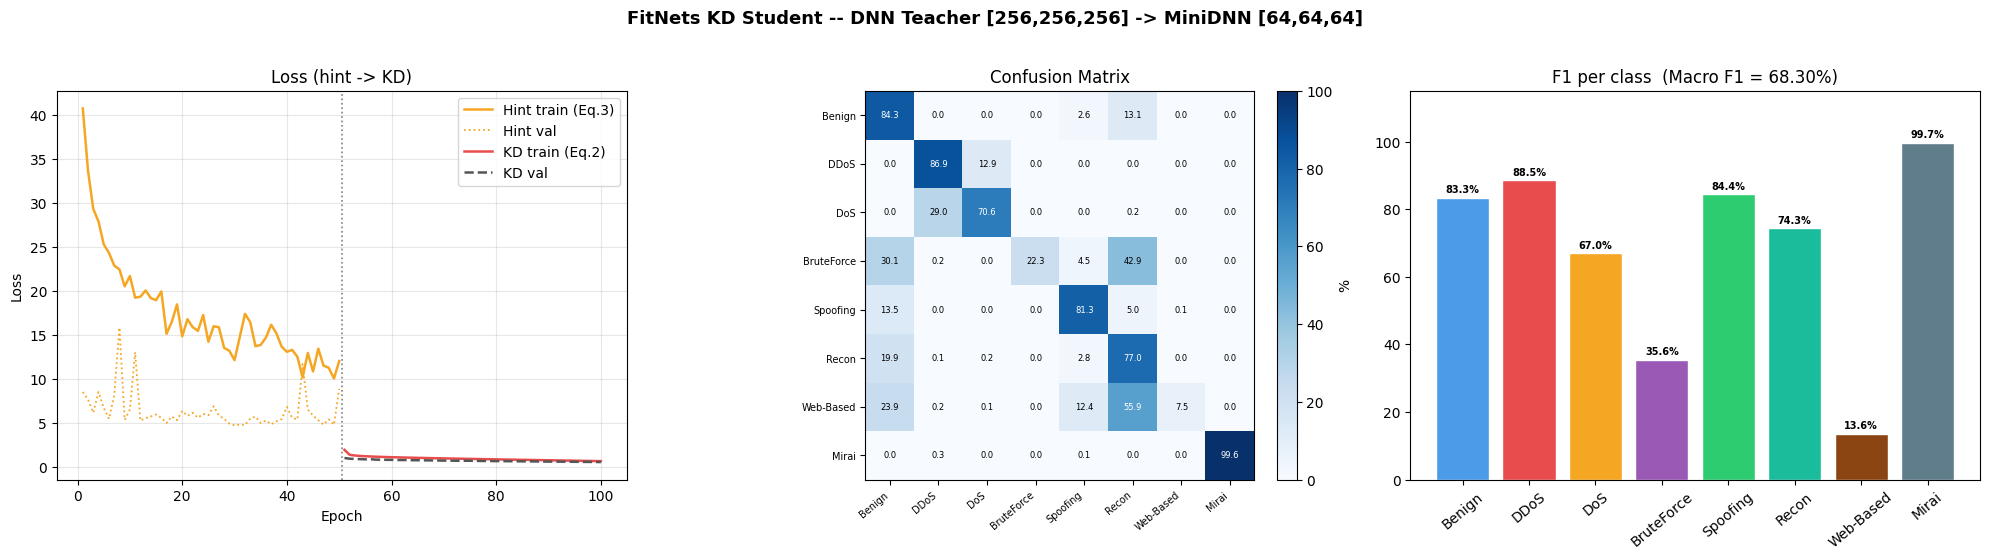

Plot -> /kaggle/working/fitnets_dnn_results.png


In [10]:
fig, axes = plt.subplots(1, 3, figsize=(20, 5.5))
fig.suptitle('FitNets KD Student -- DNN Teacher [256,256,256] -> MiniDNN [64,64,64]',
             fontsize=13, fontweight='bold', y=1.01)

ax = axes[0]
if hint_losses:
    ep_h = range(1, len(hint_losses) + 1)
    ax.plot(ep_h, hint_losses, color='#F5A623', lw=1.8, label='Hint train (Eq.3)')
    if hint_val_losses:
        ax.plot(ep_h, hint_val_losses, color='#F5A623', lw=1.3, ls=':', label='Hint val')
if train_losses:
    ep_k = range(HINT_EPOCHS + 1, HINT_EPOCHS + len(train_losses) + 1)
    ax.plot(ep_k, train_losses, color='#E84C4C', lw=1.8, label='KD train (Eq.2)')
    ax.plot(ep_k, val_losses,   color='#555555', lw=1.8, ls='--', label='KD val')
ax.axvline(HINT_EPOCHS + 0.5, color='gray', ls=':', lw=1.2)
ax.set_title('Loss (hint -> KD)'); ax.set_xlabel('Epoch'); ax.set_ylabel('Loss')
ax.legend(); ax.grid(alpha=0.3)

ax = axes[1]
cm = confusion_matrix(labels, preds)
cm_pct = cm.astype(float) / cm.sum(axis=1, keepdims=True) * 100
im = ax.imshow(cm_pct, cmap='Blues', vmin=0, vmax=100)
plt.colorbar(im, ax=ax, fraction=0.046, pad=0.04, label='%')
ax.set_xticks(range(NUM_CLASSES)); ax.set_yticks(range(NUM_CLASSES))
ax.set_xticklabels(CLASS_NAMES, rotation=40, ha='right', fontsize=7)
ax.set_yticklabels(CLASS_NAMES, fontsize=7)
ax.set_title('Confusion Matrix')
thresh = cm_pct.max() / 2
for i in range(NUM_CLASSES):
    for j in range(NUM_CLASSES):
        v = cm_pct[i, j]
        ax.text(j, i, f'{v:.1f}', ha='center', va='center',
                fontsize=6, color='white' if v > thresh else 'black')

ax = axes[2]
f1s = f1_score(labels, preds, average=None, zero_division=0)
bars = ax.bar(CLASS_NAMES, f1s*100, color=COLORS, edgecolor='white')
ax.set_ylim(0, 115)
ax.set_title(f'F1 per class  (Macro F1 = {np.mean(f1s)*100:.2f}%)')
ax.tick_params(axis='x', rotation=40)
for bar, val in zip(bars, f1s):
    ax.text(bar.get_x()+bar.get_width()/2, bar.get_height()+1.5,
            f'{val*100:.1f}%', ha='center', fontsize=7, fontweight='bold')

plt.tight_layout(rect=[0, 0, 1, 0.99])
plot_path = os.path.join(OUTPUT_DIR, 'fitnets_dnn_results.png')
plt.savefig(plot_path, dpi=150, bbox_inches='tight')
plt.show()
print(f'Plot -> {plot_path}')


## Cell 10 — Export config & ONNX

In [11]:
def export_config_onnx(student, acc, macro_auc):
    n_params = count_params(student)
    config = {
        'model'        : 'FitNets-Student-MiniDNN',
        'teacher'      : 'DNN-Plain-256-256-256',
        'num_features' : NUM_FEATURES,
        'num_classes'  : NUM_CLASSES,
        'teacher_architecture': ARCHITECTURE_TEACHER,
        'student_architecture': ARCHITECTURE_STUDENT,
        'distillation' : {
            'method'      : 'FitNets (Romero et al. 2015)',
            'stages'      : {'hint_epochs': HINT_EPOCHS, 'kd_epochs': KD_EPOCHS},
            'hint_dim'    : HINT_DIM,
            'guided_dim'  : GUIDED_DIM,
            'lambda_init' : LAMBDA_INIT, 'lambda_final': LAMBDA_FINAL,
            'tau'         : TAU,
        },
        'performance'  : {
            'accuracy'    : round(float(acc), 6),
            'macro_auc'   : round(float(macro_auc), 6),
            'params'      : n_params,
            'size_mb_fp32': round(n_params*4/1024**2, 4),
            'compression' : round(1 - n_params/t_params, 4),
        },
    }
    cfg_path = os.path.join(OUTPUT_DIR, 'config_fitnets_dnn.json')
    with open(cfg_path, 'w') as f: json.dump(config, f, indent=2)
    print(f'Config -> {cfg_path}')

    student_cpu = student.cpu().eval()
    try:
        onnx_path = os.path.join(OUTPUT_DIR, 'student_dnn_fitnets.onnx')
        torch.onnx.export(
            student_cpu, torch.randn(1, NUM_FEATURES), onnx_path,
            input_names=['features'], output_names=['logits'],
            dynamic_axes={'features':{0:'batch'},'logits':{0:'batch'}},
            opset_version=13,
        )
        sz = os.path.getsize(onnx_path)/1024
        print(f'ONNX  -> {onnx_path}  ({sz:.1f} KB)')
    except Exception as e:
        print(f'  ONNX ERROR: {e}')
    student.to(DEVICE)


export_config_onnx(student, acc, macro_auc)

print('\n' + '='*62)
print('  KET QUA FitNets Student (DNN Teacher)')
print('='*62)
print(f'  {"Accuracy":20s}: {acc*100:.4f}%')
print(f'  {"Macro AUC":20s}: {macro_auc:.6f}')
print(f'  {"Params":20s}: {count_params(student):,}')
print(f'  {"Size (MB)":20s}: {count_params(student)*4/1024**2:.4f}')
print(f'  {"Compression":20s}: {1 - count_params(student)/t_params:.1%}')
print('='*62)
print('\nOutput files:')
for fname in sorted(os.listdir(OUTPUT_DIR)):
    fp = os.path.join(OUTPUT_DIR, fname)
    if os.path.isfile(fp):
        print(f'  {fname:<45} {os.path.getsize(fp)/1024:>8.1f} KB')


Config -> /kaggle/working/config_fitnets_dnn.json
  ONNX ERROR: No module named 'onnxscript'

  KET QUA FitNets Student (DNN Teacher)
  Accuracy            : 84.3124%
  Macro AUC           : 0.977214
  Params              : 11,656
  Size (MB)           : 0.0445
  Compression         : 92.0%

Output files:
  __notebook__.ipynb                               231.1 KB
  config_fitnets_dnn.json                            0.6 KB
  fitnets_dnn_results.png                          189.9 KB
  results_fitnets_dnn.txt                            1.2 KB
  student_dnn_fitnets__classw3_37ft.pth             55.8 KB
  teacher_dnn_converted.pth                        579.9 KB
